# 03 · Avaliação de risco com MITRE ATT&CK for ICS

**Objetivo:** para cada ameaça plausível, estimar **probabilidade × consequência**, ver quanto os controles reduzem, e medir a distância entre o **SL-T** (o que cada zona precisa) e o **SL-A** (o que os controles entregam). É o coração da IEC 62443-3-2.

Cada ameaça está ligada a uma técnica do **ATT&CK for ICS**, a base pública do MITRE com o que atacantes reais fizeram em ambientes industriais. Isso evita inventar ameaças e dá um vocabulário comum com o time de segurança.

### Antes de começar

| | |
|---|---|
| **Para quem** | Quem precisa justificar investimento em segurança com algo além de "é importante". |
| **Pré-requisitos** | Notebooks 00 a 02. |
| **Tempo** | 35 minutos |

**Ao final você consegue:**

- Montar um cenário de ameaça ligado a uma técnica do ATT&CK for ICS.
- Calcular risco inerente e residual numa matriz de probabilidade e consequência.
- Explicar o que é uma contramedida compensatória.
- Ler a diferença entre SL-T e SL-A e transformá-la em plano de ação.

**Onde isso aparece na fábrica:** A avaliação de risco é o que define onde gastar. Sem ela, a segurança vira lista de desejos; com ela, cada controle tem uma ameaça e uma redução de risco para mostrar.

**Uma analogia para guardar:** É a avaliação de uma seguradora: qual a chance de acontecer, quanto custa se acontecer, e quanto cada tranca ou alarme reduz essa conta. No fim sobra um risco que alguém precisa aceitar por escrito.

> **Como estudar:** rode uma célula por vez. Sempre que aparecer **Pare e preveja**, responda mentalmente antes de executar. Errar a previsão é o que faz o conceito fixar.

In [1]:
# Configuração: raiz do repositório no caminho de import, tabelas largas
import sys, pathlib, logging, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent))
warnings.filterwarnings("ignore"); logging.disable(logging.CRITICAL)
import pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 90); pd.set_option("display.width", 200)
from IPython.display import Image, Markdown, display
from otsec.model import CAPTURES
from otsec import risk, figures
from otsec.model import threats
pd.DataFrame(threats()["threats"])[["id", "technique", "name", "zone", "likelihood", "consequence", "scenario"]]

,id,technique,name,zone,likelihood,consequence,scenario
0,TH01,T0886,Remote Services,supervision,4,4,An attacker on the office network uses the RDP path that remote support left open to t...
1,TH02,T0846,Remote System Discovery,cell,5,2,A rogue laptop plugged into the office network sweeps the cell subnet for Modbus devices
2,TH03,T0855,Unauthorized Command Message,cell,4,5,Any host that reaches port 502 can write to the PLC
3,TH04,T0836,Modify Parameter,cell,3,5,The filler speed setpoint is changed to an unsafe value
4,TH05,T0842,Network Sniffing,site_ops,4,3,MQTT in clear text exposes the SCADA account and every process value
5,TH06,T0859,Valid Accounts,site_ops,4,3,The sniffed SCADA password is reused to connect to the broker
6,TH07,T0856,Spoof Reporting Message,site_ops,3,4,A client publishes fake machine states into the UNS
7,TH08,T0830,Adversary-in-the-Middle,supervision,2,3,The historian to SCADA OPC UA link is intercepted and values are altered
8,TH09,T0814,Denial of Service,cell,3,4,A flood of Modbus requests saturates the PLC communication task
9,TH10,T0816,Device Restart/Shutdown,cell,2,4,A Modbus diagnostics request restarts the PLC communication


**Como as notas foram dadas (escala 1 a 5):**

* **Probabilidade** considera o que o exercício 01 mostrou. TH02 (descoberta) é 5 porque a rede é plana e qualquer notebook alcança a célula. TH05 (sniffing) é 4 porque o MQTT está em texto aberto.
* **Consequência** é o pior entre segurança das pessoas, produção e qualidade. TH03 e TH04 são 5: um setpoint alterado numa enchedora pode causar dano físico e perda de lote.

## 1. Risco inerente e residual

> **Pare e preveja.** Qualquer equipamento que alcança a porta 502 consegue escrever no CLP, porque o Modbus não tem autenticação. Em que faixa você colocaria esse risco numa rede plana: baixo, médio, alto ou crítico?

In [2]:
r = risk.assess()
cor = {"low": "#d5f5e3", "medium": "#fcf3cf", "high": "#fae5d3", "critical": "#fadbd8"}
(r[["id", "technique", "name", "inherent", "inherent_band", "controls", "residual", "residual_band", "missing"]]
 .style.map(lambda v: f"background-color: {cor.get(v, '')}", subset=["inherent_band", "residual_band"]))

,id,technique,name,inherent,inherent_band,controls,residual,residual_band,missing
0,TH01,T0886,Remote Services,16,high,"CTL-FW, CTL-DMZ",8,medium,CTL-MFA
1,TH02,T0846,Remote System Discovery,10,medium,"CTL-FW, CTL-IDS",4,low,
2,TH03,T0855,Unauthorized Command Message,20,critical,"CTL-FW, CTL-IDS",5,low,
3,TH04,T0836,Modify Parameter,15,high,"CTL-FW, CTL-IDS",5,low,
4,TH05,T0842,Network Sniffing,12,high,CTL-MQTT-TLS,6,medium,
5,TH06,T0859,Valid Accounts,12,high,"CTL-MQTT-AUTH, CTL-MQTT-TLS, CTL-MQTT-ACL",3,low,
6,TH07,T0856,Spoof Reporting Message,12,high,CTL-MQTT-ACL,4,low,
7,TH08,T0830,Adversary-in-the-Middle,6,medium,CTL-OPCUA-SEC,3,low,
8,TH09,T0814,Denial of Service,12,high,"CTL-FW, CTL-IDS",4,low,
9,TH10,T0816,Device Restart/Shutdown,8,medium,CTL-FW,4,low,


**Leitura**

* **TH03 (comando não autorizado ao CLP)** sai de **crítico (20)** para **baixo (5)** com o firewall entre zonas e o IDS. É a maior redução do lab, porque o Modbus não tem autenticação: a única defesa é **quem consegue chegar** na porta 502 e **quem percebe** quando algo estranho chega.
* **TH05 (sniffing)** continua **médio**: o TLS protege o MQTT, mas o Modbus da célula segue em texto aberto por limitação do protocolo. Isso é uma **contramedida compensatória** aceita na 62443: quando o componente não entrega o requisito, a arquitetura compensa.
* **TH11 e TH12** (download de programa, mídia removível) **não têm controle implementado**. O lab mostra esse risco residual em vez de escondê-lo: são os próximos itens do plano.

## 2. Mapas de calor

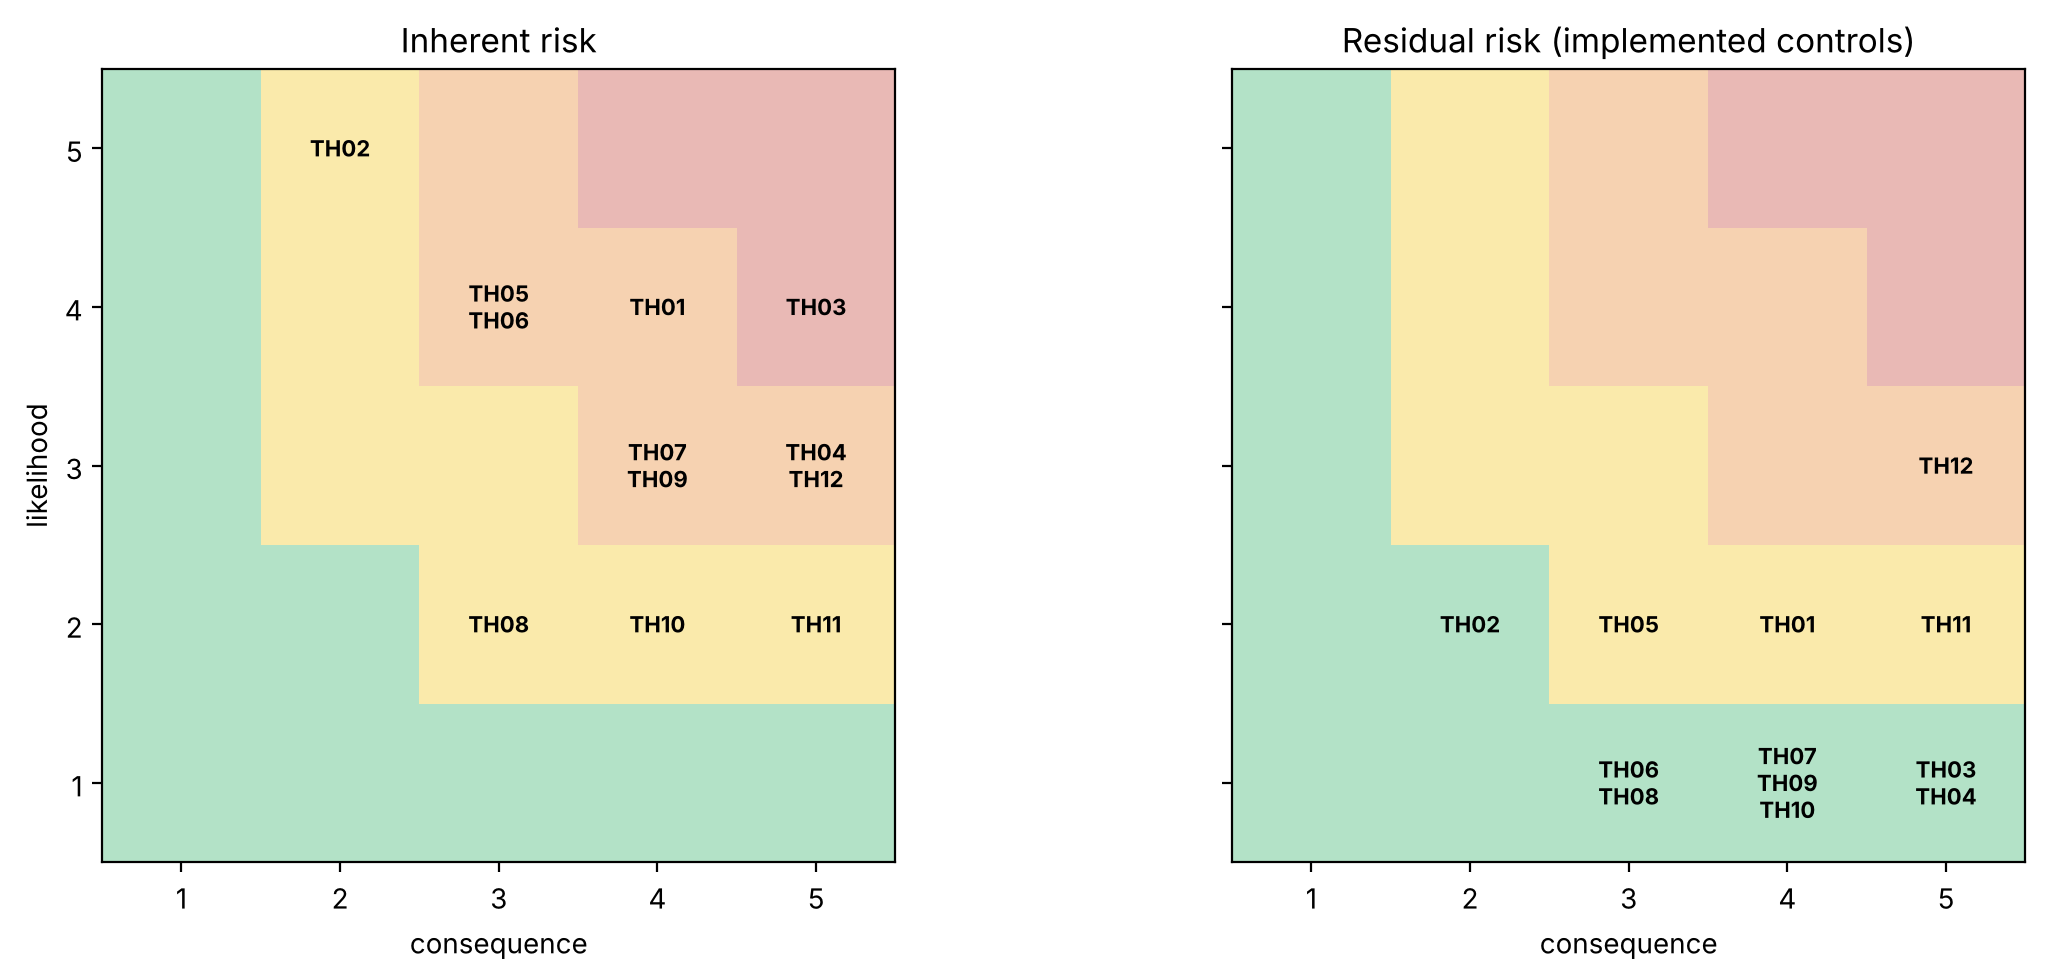

In [3]:
fig = risk.heatmaps(r); figures.save(fig, "risk_heatmap"); plt.show()

À esquerda, o retrato do exercício 01. À direita, depois dos controles dos exercícios 04 a 06. A maioria das ameaças desce para a faixa verde; TH12 fica isolada na faixa laranja, sinalizando onde investir a seguir.

## 3. SL-T contra SL-A

O SL-A aqui é uma **autoavaliação simplificada**: cada controle implementado declara até que nível ele sustenta um FR (`credit` em `model/requirements.yaml`). Não substitui uma avaliação formal, mas mostra o raciocínio.

> **Pare e preveja.** Com segmentação, criptografia e detecção implementadas, você espera que o nível alcançado (SL-A) atinja o alvo (SL-T) em todos os sete FR?

In [4]:
print("SL-A por FR com os controles implementados:", risk.sl_achieved())
g = risk.sl_gaps()
g[g.gap > 0]

SL-A por FR com os controles implementados: {'IAC': 2, 'UC': 2, 'SI': 2, 'DC': 2, 'RDF': 3, 'TRE': 2, 'RA': 2}


,zone,FR,SL_T,SL_A,gap
6,cell,RA,3,2,1
21,dmz,IAC,3,2,1
22,dmz,UC,3,2,1


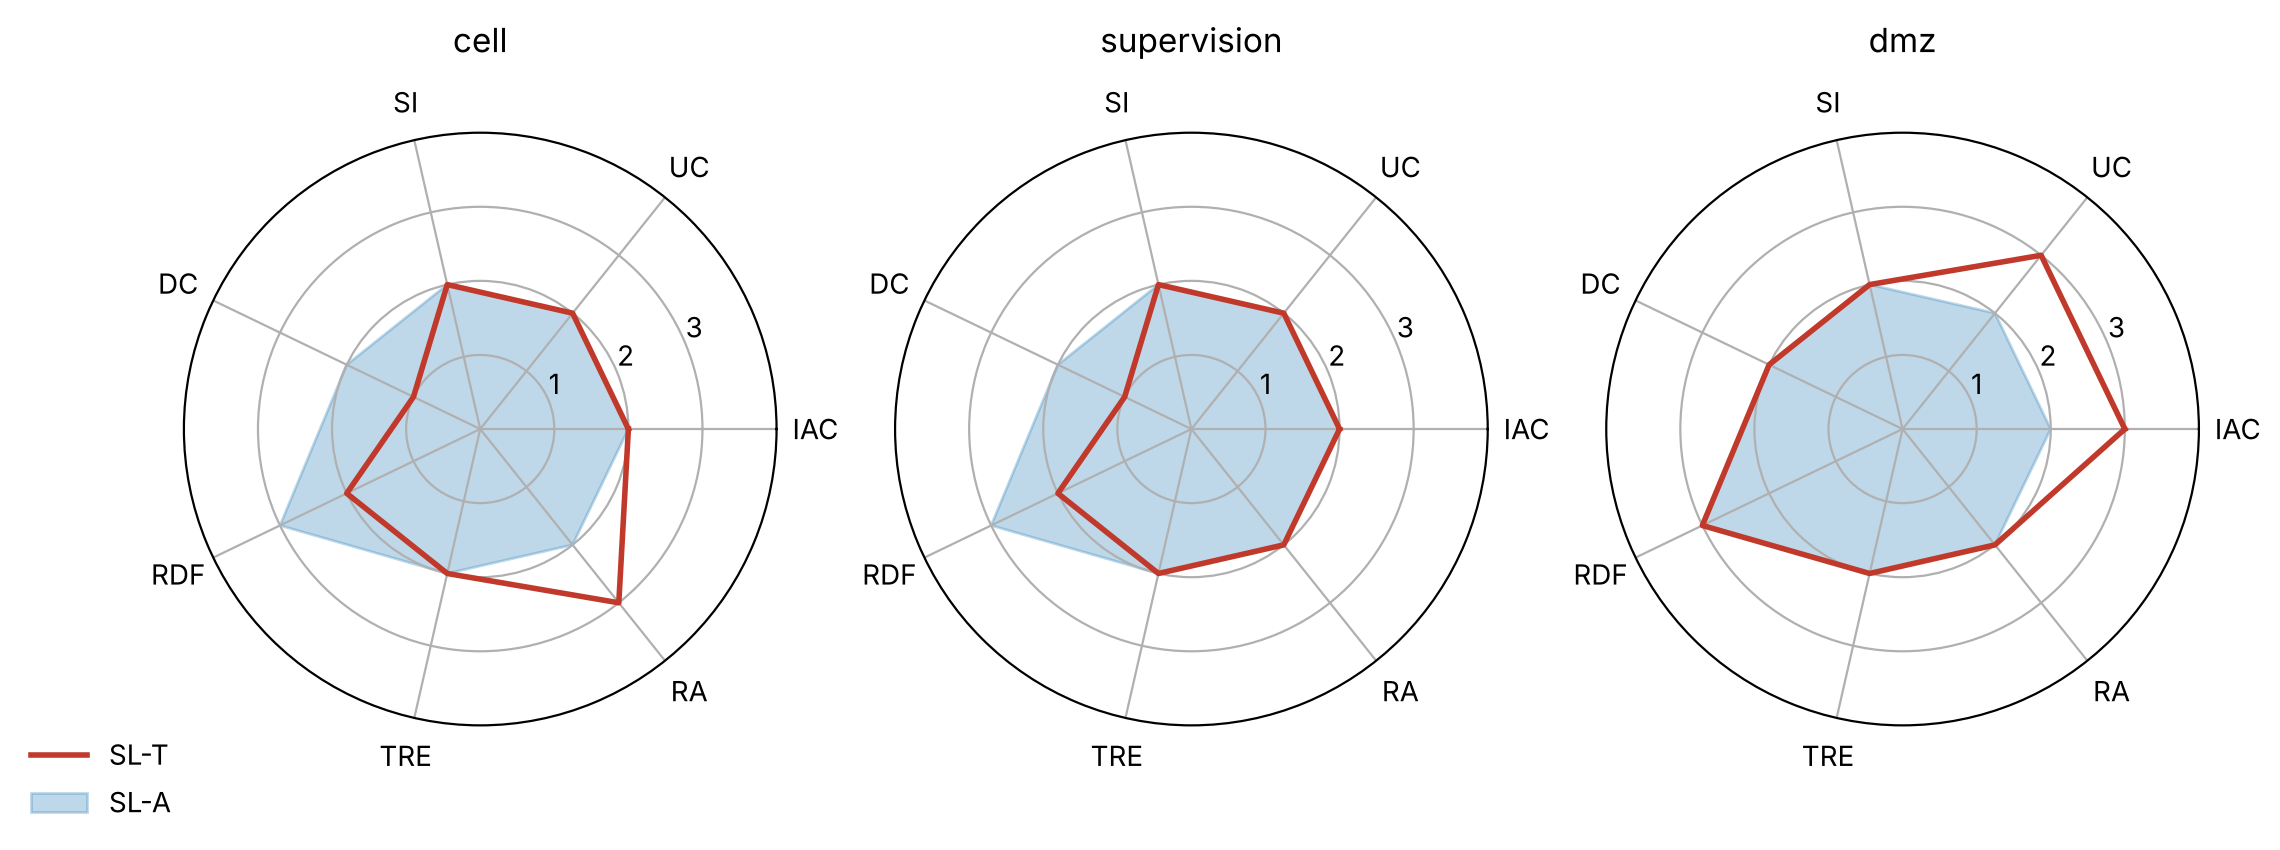

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), subplot_kw={"polar": True})
import numpy as np
from otsec.model import FR
ang = np.linspace(0, 2 * np.pi, len(FR), endpoint=False).tolist(); fecha = lambda v: list(v) + [list(v)[0]]
for ax, zona in zip(axes, ["cell", "supervision", "dmz"]):
    d = g[g.zone == zona]
    ax.plot(fecha(ang), fecha(d.SL_T), color="#c0392b", lw=2, label="SL-T")
    ax.fill(fecha(ang), fecha(d.SL_A), color="#2980b9", alpha=.3, label="SL-A")
    ax.set_xticks(ang, FR); ax.set_ylim(0, 4); ax.set_yticks([1, 2, 3]); ax.set_title(zona, pad=12)
axes[0].legend(loc="lower left", bbox_to_anchor=(-0.3, -0.2), frameon=False)
figures.save(fig, "sl_radar"); plt.show()

**Leitura:** onde a área azul (SL-A) não alcança a linha vermelha (SL-T), há trabalho a fazer.

* **Célula, RA (disponibilidade) 2 contra 3:** o IDS detecta um flood, mas nada limita a taxa de requisições. O próximo controle seria limitação de taxa no firewall ou um switch industrial com proteção de tempestade.
* **DMZ, IAC e UC 2 contra 3:** a DMZ é a fronteira com a TI e pede MFA e contas com privilégio mínimo para acesso remoto (`CTL-MFA`, planejado).

## Resumo

* Risco = probabilidade × consequência, com cada ameaça ancorada numa técnica real do ATT&CK for ICS.
* Contramedidas compensatórias são legítimas quando o protocolo não entrega (Modbus).
* A diferença SL-T menos SL-A vira o **plano de ação**, priorizado pelo risco residual.

---
## Erros comuns

- **Inventar ameaças.** Use um catálogo como o ATT&CK for ICS. Ameaça sem base vira discussão de opinião.
- **Avaliar só o impacto em dados.** Em OT a consequência inclui segurança das pessoas, meio ambiente e produção.
- **Dar um controle como solução total.** Cada controle reduz parte da probabilidade. O risco residual precisa aparecer.
- **Esconder o que não foi resolvido.** O risco que sobra precisa de dono e de plano. Omitir é pior que mostrar.

## Teste seu entendimento

Responda antes de abrir cada resposta.

**1. Qual a diferença entre risco inerente e residual?**

<details><summary>Ver resposta</summary>

Inerente é o risco sem nenhum controle. Residual é o que resta depois dos controles implementados.

</details>

**2. O Modbus da célula continua sem criptografia. Como o risco de comando não autorizado caiu tanto?**

<details><summary>Ver resposta</summary>

Por contramedidas compensatórias: o firewall limita quem alcança a porta 502 e o IDS detecta o que foge do padrão. Quando o protocolo não oferece o requisito, a arquitetura compensa.

</details>

**3. Por que a ameaça de mídia removível continua na faixa alta?**

<details><summary>Ver resposta</summary>

Porque nenhum controle para ela foi implementado ainda. O laboratório mostra essa lacuna como item planejado.

</details>

## Exercícios para praticar

1. Acrescente um cenário para acesso remoto de fornecedor: técnica, zona, probabilidade, consequência e controles.
2. Marque o controle de MFA como implementado no modelo e veja quais riscos e quais lacunas de SL mudam.
3. Escolha o risco residual mais alto e escreva uma justificativa de investimento em três frases.

## Glossário

| Termo | Significado |
|---|---|
| **Risco inerente** | Risco antes de qualquer controle. |
| **Risco residual** | Risco que permanece depois dos controles. |
| **Contramedida compensatória** | Controle que supre um requisito que o componente não atende sozinho. |
| **Técnica (ATT&CK)** | Uma forma específica e catalogada de atacar. |
| **SL-A** | Nível de segurança alcançado na instalação. |
| **Mapa de calor** | Matriz de probabilidade por consequência, colorida por faixa de risco. |

**Próximo passo:** [04 · Segmentação na prática](04_segmentacao_na_pratica.ipynb), onde o desenho vira um firewall testado.